# E2E 5G Drive-Test KPI Analyzer

From raw drive-test logs to findings: **load → clean → KPI statistics → cell changes → maps → throughput prediction**.

* **Data:** 16 drive tests in Cork, Ireland (Dec 2019 to Feb 2020), logged with G-NetTrack Pro on a commercial network. A file download runs during the whole drive. Source: Raca, Leahy, Sreenan, Quinlan, *Beyond Throughput, The Next Generation: A 5G Dataset with Channel and Context Metrics*, ACM MMSys 2020 ([uccmisl/5Gdataset](https://github.com/uccmisl/5Gdataset), GPL-3.0).
* **Code:** all logic lives in the `drivetest` package next to this notebook. The notebook only calls it and explains the results.
* **How to run:** run the cells from top to bottom. The first cell downloads the code (on Google Colab) and the second downloads the dataset.

## 0. Setup

In [1]:
# On Google Colab this downloads the project code. On your own computer
# (notebook opened from the project folder) the folder is already there.
import os
REPO_URL = "https://github.com/Shaibu-github/5g-drive-test-kpi-analyzer.git"
if not os.path.exists("drivetest"):
    !git clone -q {REPO_URL} project
    os.chdir("project")

import pandas as pd
from drivetest import data, clean, kpi, handover, maps, model, plots

pd.set_option("display.max_columns", 30)

## 1. Load the raw logs

Each CSV file is one drive. Each row is one sample, about one per second, with position, serving cell, radio KPIs and the measured bitrate.

In [2]:
root = data.download_dataset("data")       # downloads once (2 MB), then reuses the folder
paths = data.list_logs(root)               # the Download/Driving logs
raw = data.load_logs(paths)

print(len(paths), "drive logs,", raw.shape[0], "samples,", raw.shape[1], "columns")
raw.head()

16 drive logs, 27591 samples, 27 columns


,Timestamp,Longitude,Latitude,Speed,Operatorname,CellID,NetworkMode,RSRP,RSRQ,SNR,CQI,RSSI,DL_bitrate,UL_bitrate,State,PINGAVG,PINGMIN,PINGMAX,PINGSTDEV,PINGLOSS,CELLHEX,NODEHEX,LACHEX,RAWCELLID,NRxRSRP,NRxRSRQ,drive
0,2019.12.14_10.16.30,-8.388186,51.935604,0,B,12,5G,-99,-15.0,6.0,12.0,-90.0,7,1,D,NaN,NaN,NaN,NaN,NaN,C,A81B,9CBA,11016972,-100.0,-15.0,2019.12.14_10.16.30
1,2019.12.14_10.16.31,-8.388470,51.935739,1,B,12,5G,-99,-15.0,6.0,12.0,-90.0,7,1,D,NaN,NaN,NaN,NaN,NaN,C,A81B,9CBA,11016972,-100.0,-15.0,2019.12.14_10.16.30
2,2019.12.14_10.16.31,-8.388470,51.935739,1,B,12,5G,-99,-15.0,6.0,12.0,-90.0,0,0,D,NaN,NaN,NaN,NaN,NaN,C,A81B,9CBA,11016972,-100.0,-15.0,2019.12.14_10.16.30
3,2019.12.14_10.16.32,-8.388470,51.935739,1,B,12,5G,-102,-14.0,6.0,12.0,-90.0,0,0,D,NaN,NaN,NaN,NaN,NaN,C,A81B,9CBA,11016972,-99.0,-15.0,2019.12.14_10.16.30
4,2019.12.14_10.16.33,-8.388470,51.935739,1,B,12,5G,-102,-14.0,6.0,12.0,-90.0,9,12,D,NaN,NaN,NaN,NaN,NaN,C,A81B,9CBA,11016972,-99.0,-15.0,2019.12.14_10.16.30


### Look before you trust

A drive-test log is never clean. Before any statistics, check what the logger really wrote.

In [3]:
print("Samples per network mode:")
print(raw["NetworkMode"].value_counts().to_string(), "\n")
print("Lowest RSRP:", raw["RSRP"].min(), "dBm   | largest neighbour RSRQ:", raw["NRxRSRQ"].max())
print("Repeated timestamps inside a drive:", raw.duplicated(["drive", "Timestamp"]).sum())
print("Different CellID values:", raw["CellID"].nunique(), "  | different RAWCELLID values:", raw["RAWCELLID"].nunique())
print("\nMissing values (%):")
(raw.isna().mean() * 100).round(1).sort_values(ascending=False).head(9)

Samples per network mode:
NetworkMode
5G       13959
LTE       9204
HSPA+     4338
HSDPA       41
HSUPA       41
UMTS         8 

Lowest RSRP: -200 dBm   | largest neighbour RSRQ: 2147483647.0
Repeated timestamps inside a drive: 3145
Different CellID values: 27   | different RAWCELLID values: 111

Missing values (%):


PINGMIN      92.8
PINGSTDEV    92.8
PINGMAX      92.8
PINGAVG      92.8
PINGLOSS     92.6
NRxRSRQ      24.3
RSSI         18.3
CQI          16.1
SNR          16.0
dtype: float64

What this shows:

* **RSRP = -200 dBm** and **RSRQ = 2147483647** are impossible. They are placeholders the logger writes when it has no measurement (2147483647 is the largest 32-bit integer).
* **Timestamps repeat** 3,145 times. These are not duplicated rows: the logger samples about once per second but writes whole seconds, so two samples can share a second. Their bitrates differ, so both are kept.
* **Ping columns are about 93% empty**, so they are dropped.
* **`CellID` is not the cell.** There are 27 `CellID` values but 111 `RAWCELLID` values. The next cell shows why.

In [4]:
# "CellID 12" exists on many different sites (NODEHEX = eNB ID in hex)
print(raw[raw["CellID"] == 12].groupby("NODEHEX").size().to_string())

# RAWCELLID is the full E-UTRAN cell identity: eNB ID * 256 + cell number
print("\neNB A81B, cell 12 ->", int("A81B", 16) * 256 + 12)

NODEHEX
A4DF       6
A4E8     465
A4EF      12
A515       3
A700      30
A701     153
A705     102
A706      21
A707     240
A709     560
A710     327
A81B    1021
A992     315
A99B     477
A99D      57
A9AA     110
A9B0     232
A9B6      22

eNB A81B, cell 12 -> 11016972


`CellID` is only the cell number inside a site (like a sector number). The real identity is `RAWCELLID` = eNB ID × 256 + cell number, the standard 28-bit LTE cell identity. **A change between two sites that both have a "sector 12" is invisible if you only watch `CellID`.** The rest of the analysis uses `RAWCELLID`.

One more observation: rows marked **5G** also carry a 28-bit *LTE* cell identity. That fits a 5G non-standalone (NSA) network: the phone is anchored on an LTE cell and the NR carrier is added on top. So in "5G" rows the cell and, most likely, the radio KPIs describe the **LTE anchor**, not the NR carrier. Section 3 tests this idea with data.

## 2. Clean

`clean.clean()` applies seven rules. Rows are never deleted; a bad value becomes `NaN` and the rest of the row is kept.

1. Parse the timestamp text into real times.
2. Group the six network modes into three technologies: 5G, LTE, 3G.
3. Replace impossible radio values with `NaN`.
4. On 3G rows, blank the columns that only hold placeholders (RSRQ is almost always -2, neighbour RSRP always -51). The 3G signal level (RSCP, logged in the RSRP column) is real and is kept.
5. Convert bitrates from kbps to Mbps.
6. Fix the GPS: remove a stale first position and measure the distance moved.
7. Flag rows where the cell identity does not fit the technology (`identity_ok`).

In [5]:
df = clean.clean(raw)
clean.cleaning_report(raw, df)

,missing_in_raw,blanked_by_cleaning,valid_after_cleaning,valid_pct
column,,,,
rsrp,0,3,27588,100.0
rsrq,3402,1183,23006,83.4
snr,4428,3,23160,83.9
cqi,4429,0,23162,83.9
rssi,5038,0,22553,81.7
nbr_rsrp,4047,3837,19707,71.4
nbr_rsrq,6711,2291,18589,67.4


In [6]:
print(kpi.overview(df))
df.head(3)

{'drives': 16, 'samples': 27591, 'hours': 7.9, 'route_km': 168.4, 'cells': 111, 'sites': 51, 'rows_with_identity_mismatch': 191, 'first_day': '2019-12-14', 'last_day': '2020-02-27'}


,drive,time,elapsed_s,sample,lat,lon,gps_fix,step_m,speed_kmh,tech,network_mode,cell,site,sector,identity_ok,rsrp,rsrq,snr,cqi,rssi,nbr_rsrp,nbr_rsrq,dl_mbps,ul_mbps,state
0,2019.12.14_10.16.30,2019-12-14 10:16:30,0.0,0,51.935604,-8.388186,1,0.000000,0,5G,5G,11016972,A81B,12,True,-99.0,-15.0,6.0,12.0,-90.0,-100.0,-15.0,0.007,0.001,D
1,2019.12.14_10.16.30,2019-12-14 10:16:31,1.0,1,51.935739,-8.388470,2,24.585061,1,5G,5G,11016972,A81B,12,True,-99.0,-15.0,6.0,12.0,-90.0,-100.0,-15.0,0.007,0.001,D
2,2019.12.14_10.16.30,2019-12-14 10:16:31,1.0,2,51.935739,-8.388470,2,0.000000,1,5G,5G,11016972,A81B,12,True,-99.0,-15.0,6.0,12.0,-90.0,-100.0,-15.0,0.000,0.000,D


The campaign: **16 drives, 7.9 hours, 168 km, 111 cells on 51 sites.**

Two details to remember:

* **GPS.** The logger writes a new position only about every 100 m, so position and speed stay frozen between two updates (the speed never reads 0 at a stop). That is why the maps in section 5 use 100 m bins and why speed is not used as a model input.
* **Rule 7.** An LTE cell identity is eNB ID × 256 + cell number; a 3G one is RNC ID × 65536 + cell number. In 191 rows (0.7%) the formula fails: when the phone changes technology, the logger sometimes updates the network mode and the cell identity in different rows. Those rows are flagged and left out of the cell and site counts.

## 3. KPI statistics

First question of any drive test: what did the phone camp on, and how good was it?

In [7]:
print("Share of samples per technology (%):")
print(kpi.tech_share(df).to_string(), "\n")
kpi.radio_summary(df)

Share of samples per technology (%):
tech
5G     50.6
LTE    33.4
3G     16.0 



,samples,rsrp_median,rsrp_p10,rsrq_median,rsrq_p10,snr_median,snr_p10,cqi_median,cqi_p10
5G,13959.0,-83.0,-97.0,-12.0,-16.0,4.0,-6.0,12.0,7.0
LTE,9204.0,-88.0,-104.0,-12.0,-15.0,3.0,-4.0,9.0,6.0
3G,4428.0,-69.0,-89.0,NaN,NaN,NaN,NaN,NaN,NaN


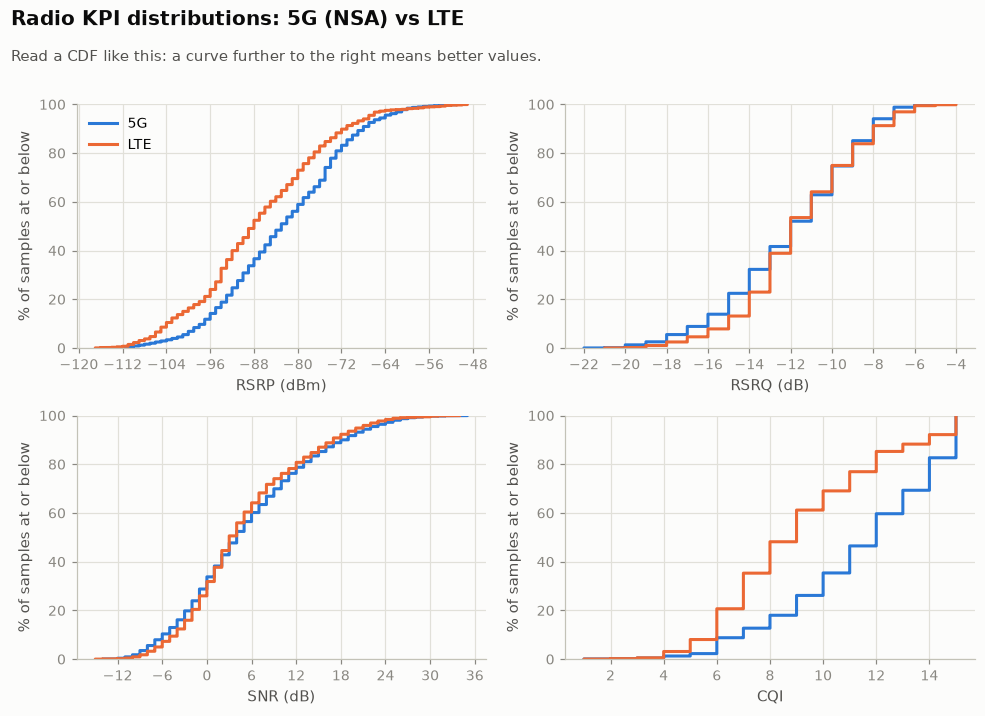

In [8]:
plots.radio_cdfs(df);

* 5G rows have better **RSRP** than LTE rows (median -83 vs -88 dBm; cell-edge 10th percentile -97 vs -104 dBm) and a clearly higher **CQI** (median 12 vs 9).
* **RSRQ** and **SNR** are almost the same on both.

rsrp,Poor (below -100 dBm),Fair (-100 to -90),Good (-90 to -80),Excellent (-80 or better)
tech,,,,
5G,5.5,22.2,28.4,43.9
LTE,15.0,27.8,26.7,30.5


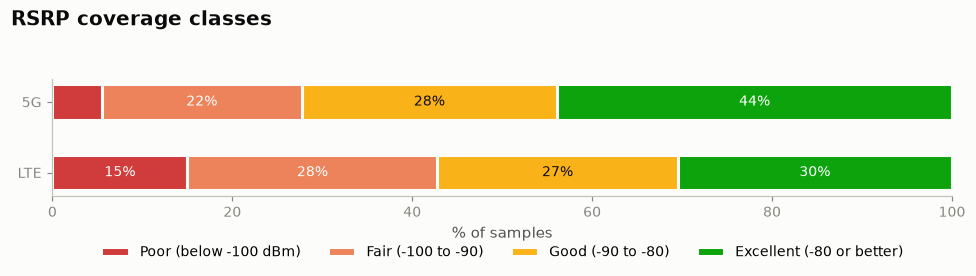

In [9]:
display(kpi.coverage_classes(df))
plots.coverage_bars(df);

### Throughput

,samples,mean_mbps,p10_mbps,median_mbps,p90_mbps,max_mbps,pct_below_1mbps
5G,13880.0,46.4,0.0,15.9,157.4,532.9,14.6
LTE,9125.0,11.2,0.0,6.8,21.1,372.5,15.7
3G,3746.0,3.5,0.0,2.5,8.0,22.8,29.2


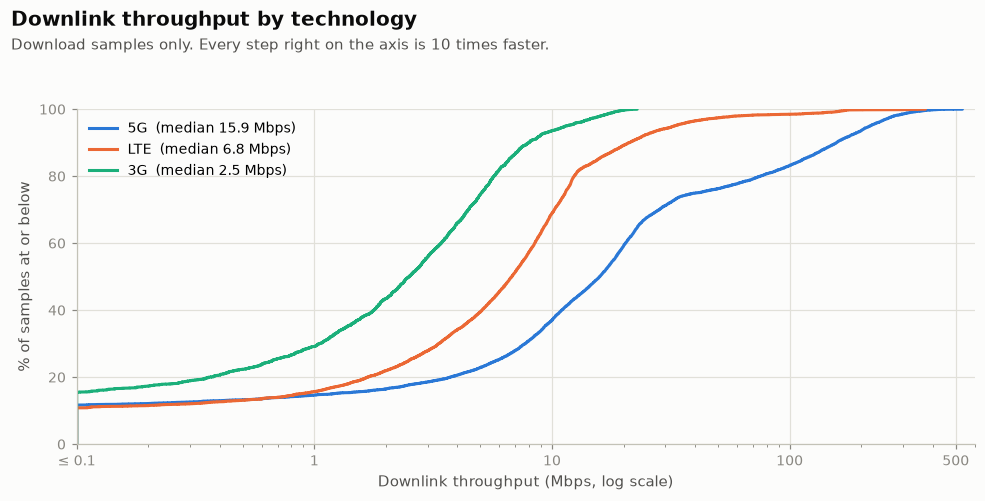

In [10]:
display(kpi.throughput_summary(df))
plots.throughput_cdf(df);

Throughput statistics use only samples where the download is running (state `D`). In idle or voice states a low bitrate says nothing about the radio link.

* **Median downlink: 5G 15.9 Mbps, LTE 6.8 Mbps, 3G 2.5 Mbps.**
* The 5G curve has a long tail: the best 10% of 5G samples are above 157 Mbps, and the mean (46 Mbps) is three times the median. 5G gives very high peaks, but not everywhere.
* About 15% of LTE and 5G samples are below 1 Mbps even though the download is running: stalls.

### Does better channel quality give more throughput?

This is the link-adaptation question. The phone reports CQI; the scheduler picks the modulation and coding from it. Better CQI should mean more bits per resource block.

,5G,LTE
rsrp,0.24,0.21
rsrq,0.01,0.23
snr,0.10,0.25
cqi,0.02,0.27


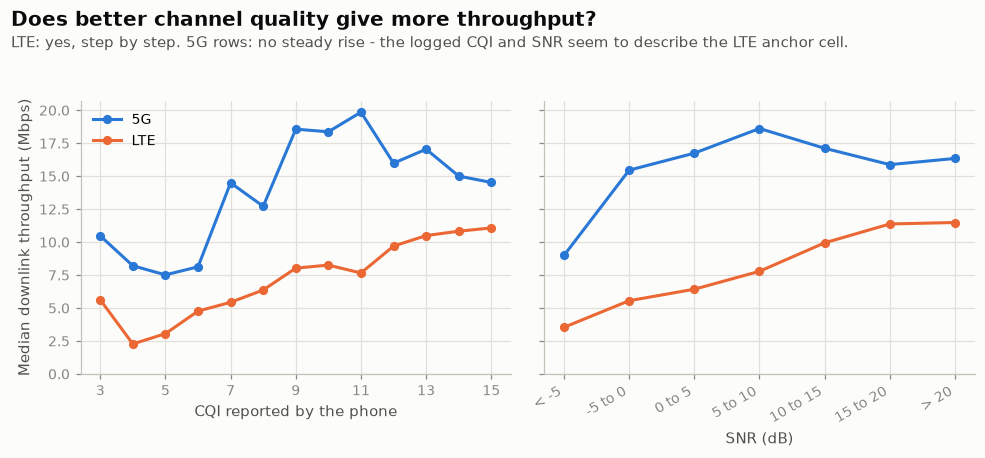

In [11]:
display(kpi.correlation_with_throughput(df))
plots.link_adaptation(df);

* **LTE behaves as expected:** median throughput climbs step by step from about 2 Mbps at CQI 4 to 11 Mbps at CQI 15, and the same with SNR.
* **5G rows do not:** there is no steady rise. The median peaks around CQI 11 and falls again, and the rank correlation between CQI and throughput is 0.02 (LTE: 0.27).

This supports the idea from section 1. In NSA most of the bits flow over the NR carrier, but the logged CQI and SNR seem to belong to the LTE anchor. **The KPIs in a "5G" row cannot explain 5G throughput.** RSRP still helps a little (0.24), probably because the NR antennas sit on the same sites, so a strong anchor often means a strong NR signal.

The correlations are low everywhere (below 0.3). What the phone cannot see matters more: how many users share the cell, the bandwidth, and what the scheduler gives this user.

## 4. Serving-cell changes

**Limit of this data:** G-NetTrack is an application-level logger. It does not see RRC signalling, so it cannot show measurement reports or handover commands. What it shows is the moment the serving cell or technology is different from the previous sample. That can be a handover, a cell reselection or a re-establishment after a radio link failure. This notebook calls all of them **cell changes**.

In [12]:
events = handover.find_cell_changes(df)
events = handover.mark_ping_pong(events, max_stay_s=5)
print(len(events), "cell changes")
events.head()

733 cell changes


,drive,sample,time,elapsed_s,lat,lon,speed_kmh,from_tech,to_tech,from_cell,to_cell,from_site,to_site,rsrp_before,rsrp_after,kind,stay_s,ping_pong_return,ping_pong
event,,,,,,,,,,,,,,,,,,,
0,2019.12.14_10.16.30,135,2019-12-14 10:18:54,144.0,51.931551,-8.392812,54,5G,5G,11016972,11016973,A81B,A81B,-90.0,-96.0,5G intra-site,144.0,False,False
1,2019.12.14_10.16.30,404,2019-12-14 10:23:26,416.0,51.925379,-8.404444,60,5G,5G,11016973,11115276,A81B,A99B,-96.0,-91.0,5G inter-site,272.0,False,False
2,2019.12.14_10.16.30,452,2019-12-14 10:24:09,459.0,51.920776,-8.411916,52,5G,5G,11115276,11115277,A99B,A99B,-90.0,-83.0,5G intra-site,43.0,False,False
3,2019.12.14_10.16.30,484,2019-12-14 10:24:39,489.0,51.919327,-8.417487,63,5G,LTE,11115277,70839810,A99B,438EE,-95.0,-95.0,5G to LTE,30.0,False,False
4,2019.12.14_10.16.30,504,2019-12-14 10:24:58,508.0,51.918262,-8.421668,53,LTE,5G,70839810,11115277,438EE,A99B,-109.0,-102.0,LTE to 5G,19.0,False,False


In [13]:
rate = handover.rate_per_drive(df, events)
print("All drives together:", round(len(events) / rate["minutes"].sum(), 2), "changes per minute,",
      round(len(events) / rate["km"].sum(), 2), "per km\n")
handover.summarize_by_kind(events)

All drives together: 1.54 changes per minute, 4.35 per km



,changes,ping_pong_pct,median_stay_s,median_rsrp_before,median_rsrp_gain_db
kind,,,,,
5G inter-site,234,42.7,8.5,-86.0,1.0
5G to LTE,135,35.6,7.0,-89.0,0.0
LTE to 5G,131,38.9,17.0,-91.0,2.0
LTE inter-site,91,42.9,13.0,-97.0,2.0
5G intra-site,80,25.0,32.0,-76.0,1.0
LTE intra-site,35,11.4,33.0,-80.0,4.0
3G cell change,15,0.0,28.0,-87.0,0.0
LTE to 3G,6,0.0,2.5,-115.5,NaN
3G to LTE,3,0.0,288.0,-59.0,NaN


**733 cell changes: 1.5 per minute, 4.4 per km.** The typical RSRP gain of a change is small, 0 to 2 dB for the common kinds: the phone is moved when the two cells are almost equal.

### Ping-pong

A ping-pong is a round trip A → B → A with only a short stay on B. The time limit is a choice, so the table shows how much the answer depends on it.

In [14]:
handover.ping_pong_sensitivity(events)

,round_trips,changes_in_a_round_trip,pct_of_changes
max_stay_s,,,
2,79,150,20.5
3,112,207,28.2
5,148,262,35.7
10,206,346,47.2


* With a limit of 5 seconds there are **148 round trips**, and 262 of the 733 changes (**36%**) are the way out or the way back of one.
* The share moves from 21% (2 s) to 47% (10 s), so "about a third" is the honest summary, not a precise figure.
* Changes between sites and between technologies are part of a ping-pong most often (36 to 43%); changes between two sectors of the same LTE site least often (11%).

A caution: the log cannot prove that every A → B → A is a real double handover. In either case these are unstable borders where the serving cell is not settled.

### What does a cell change look like?

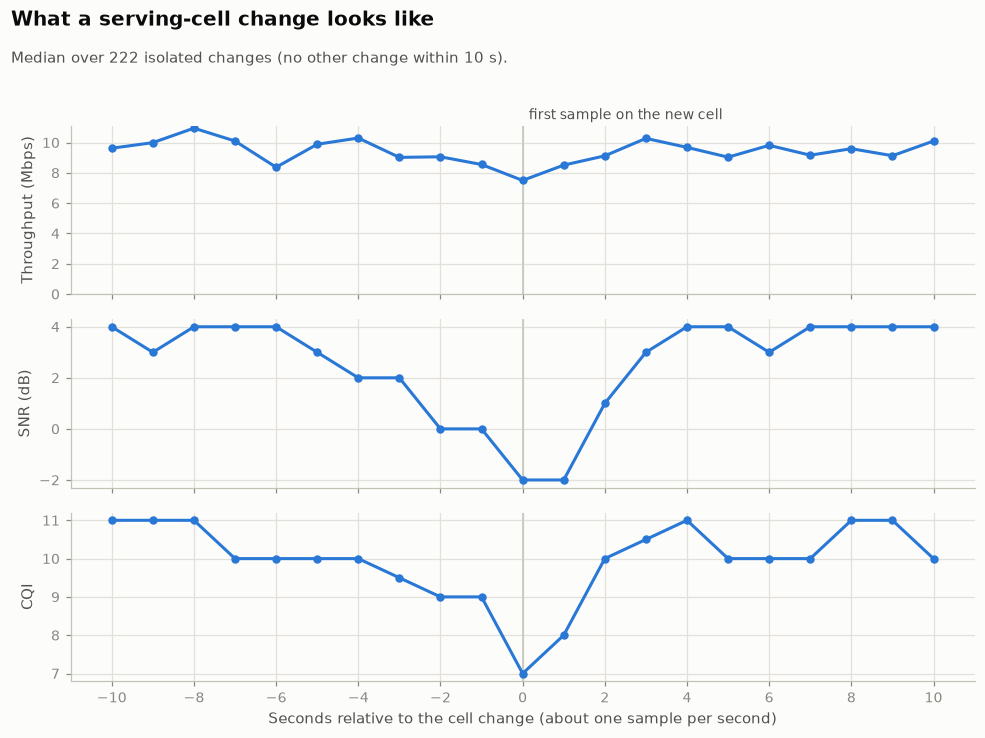

In [15]:
plots.change_profile(df, events);

The figure uses the 222 **isolated** changes (no other change within 10 samples), so "before" and "after" each belong to one cell.

**SNR falls from 4 dB to 0 dB in the last seconds before the change, is at -2 dB on the first two samples on the new cell, and is back at 4 dB four seconds after it.** CQI follows: 11, then 9, then 7, then 11 again. At the border the two cells are about equally strong, so whichever one serves, the other is a strong interferer. Throughput dips at the same moment.

### What does a cell change cost?

In [16]:
isolated = handover.isolated(events)
dips = handover.dip_per_event(handover.throughput_window(df, isolated))
display(handover.dip_summary(dips))

# control group: the same measurement at 3,000 random moments
control = handover.dip_per_event(handover.throughput_window(df, handover.random_moments(df)))
print("Random moments, median drop:", handover.dip_summary(control).loc["All changes", "median_drop_pct"], "%")

,events,before_mbps,around_mbps,after_mbps,median_drop_pct,drop_low,drop_high,median_after_vs_before_pct,after_low,after_high
All changes,201.0,14.0,8.8,11.7,30.8,5.1,39.7,-6.8,-20.7,4.1
5G inter-site,44.0,47.8,23.2,36.1,39.6,-7.5,57.8,-19.2,-42.3,3.8
5G intra-site,43.0,28.9,15.2,24.7,10.5,-38.5,71.6,6.3,-18.7,37.4
5G to LTE,38.0,26.8,7.1,6.2,57.2,33.2,76.6,-76.6,-84.7,-65.1
LTE inter-site,24.0,6.6,6.8,6.5,-6.1,-44.6,13.3,8.3,-23.6,77.5
LTE to 5G,24.0,7.1,4.6,15.2,28.5,-60.7,54.3,198.7,88.0,398.5
LTE intra-site,23.0,9.5,7.6,7.3,14.6,-24.5,37.7,-5.7,-25.9,17.7


Random moments, median drop: -4.5 %


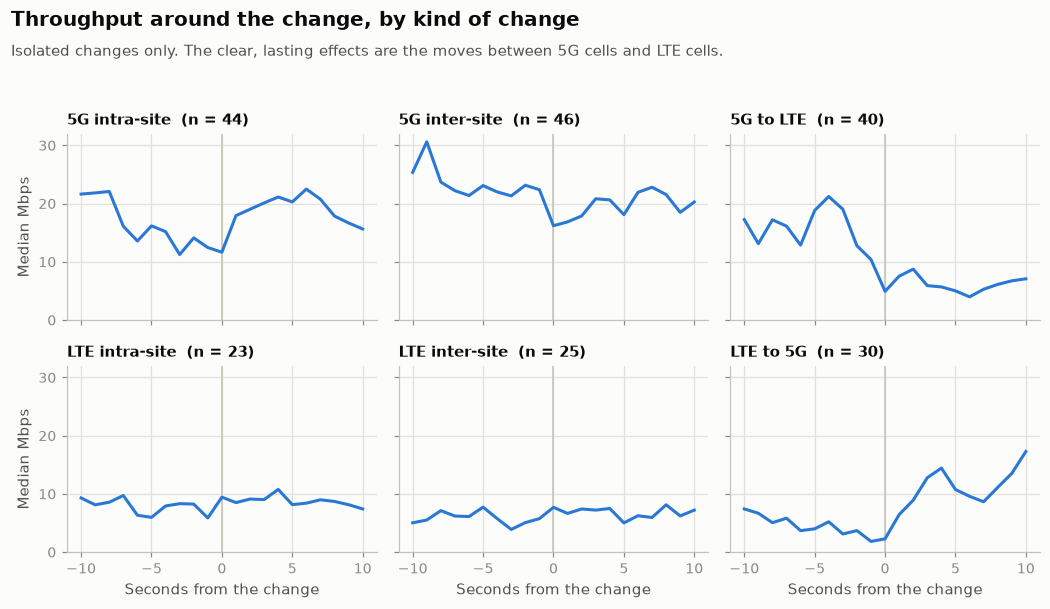

In [17]:
plots.change_profile_by_kind(df, events);

How to read the table: `median_drop_pct` is how much lower the throughput is around the change than before it; `drop_low` and `drop_high` are a 95% bootstrap interval. An interval that includes 0 means the data cannot show an effect. Only events with at least 1 Mbps before the change are used (201 of the 222).

* **All changes together: about 31% lower** around the change, with a wide interval (5% to 40%). At random moments the same calculation gives no dip (-4.5%), so the dip is real, but its size is not known precisely.
* **5G → LTE is the one clear case:** 57% lower at the change (33% to 77%), and still 77% lower afterwards.
* **LTE → 5G:** throughput is about three times higher a few seconds later (+199%, interval +88% to +399%).
* **For the other kinds the intervals include 0.** With 23 to 44 events each, this data cannot say what a change between two sites or two sectors costs.

**What "5G to LTE" means here.** The 5G-mode cells and the LTE-mode cells are almost separate sets (49 and 55 cells, 2 in both). A change from 5G to LTE is always a change of cell, and in 127 of 135 cases a change of site. So the large loss is the cost of leaving the 5G-capable cells.

**Why this matters for RAN traffic control.** Handover parameters (A3 offset, hysteresis, time-to-trigger) decide when the change happens. Margins that are too small give ping-pong; margins that are too large give radio link failures. On these routes the two things to look at first are the site borders, where most ping-pong happens, and the edge of the 5G layer, because falling back to an LTE cell is the one change with a clear and lasting cost.

## 5. Maps

The same roads were driven many times. Instead of 16 drives drawn on top of each other, each sample goes into a 100 m × 100 m road bin, and the bin shows the median over all drives.

432 road bins
problem
Weak coverage                        41
Low throughput with good coverage     2


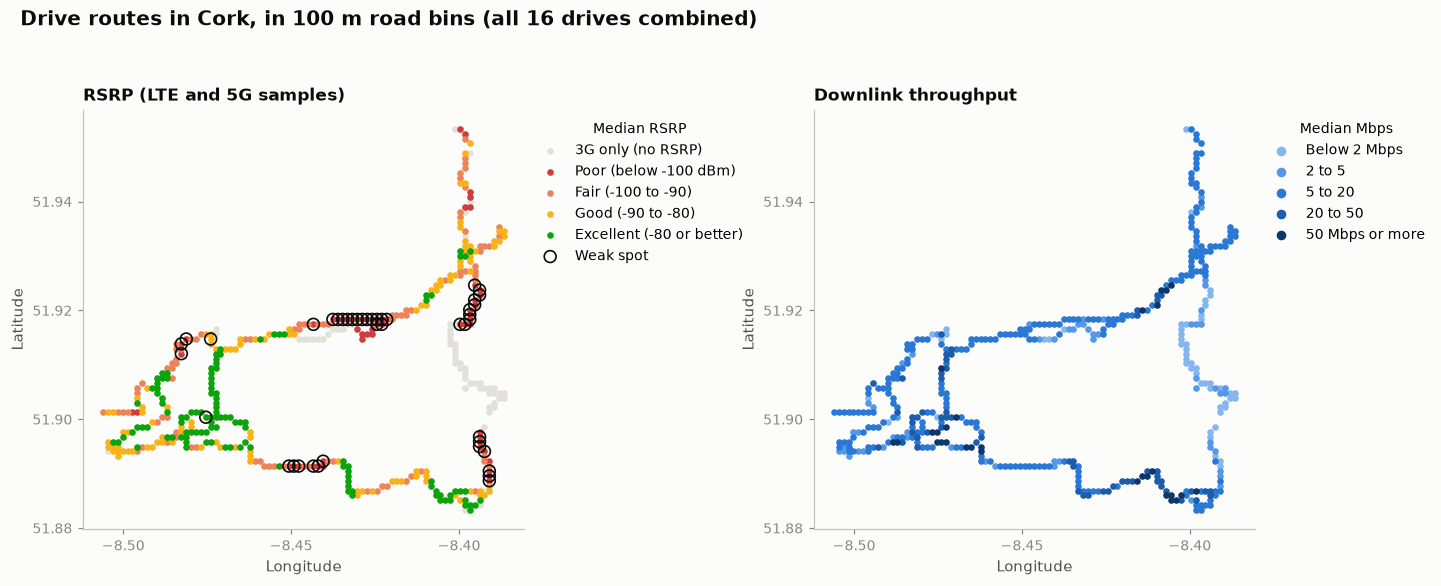

In [18]:
bins = maps.road_bins(df, events)
spots = maps.weak_spots(bins)
print(len(bins), "road bins")
print(spots["problem"].value_counts().to_string())
plots.coverage_maps(bins, spots);

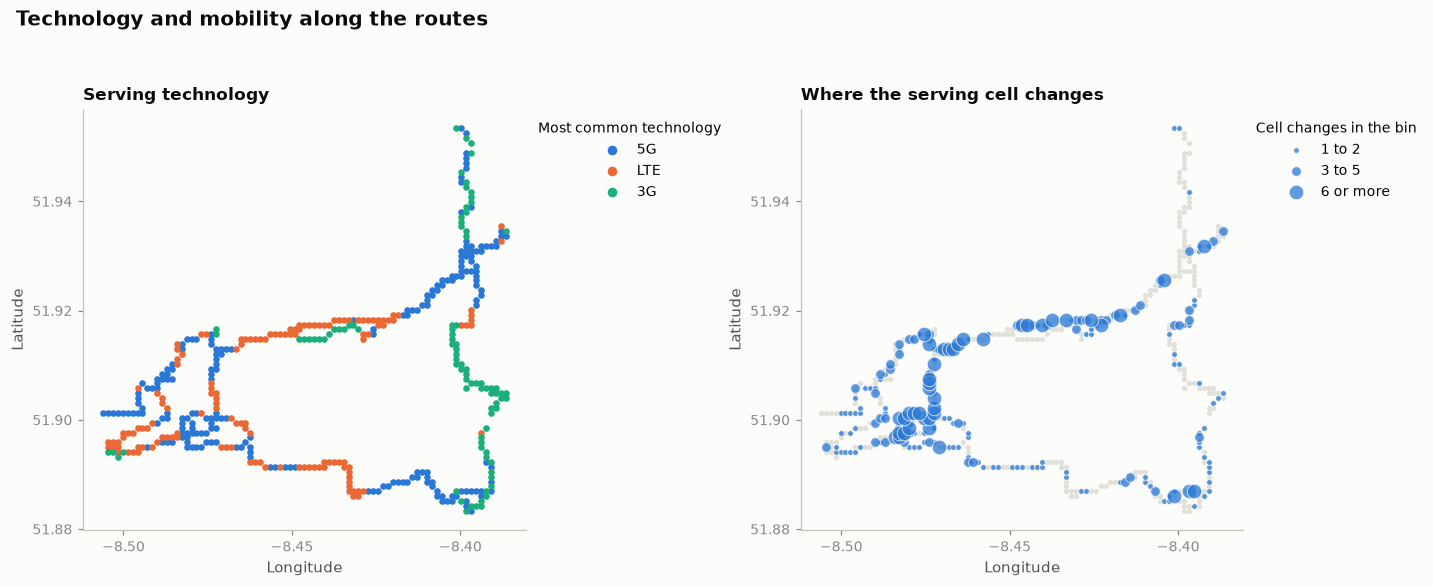

In [19]:
plots.mobility_maps(bins);

In [20]:
maps.interactive_map(bins, events, spots, "figures/interactive_map.html")
print("Saved figures/interactive_map.html - open it in a browser to zoom and switch layers.")

Saved figures/interactive_map.html - open it in a browser to zoom and switch layers.


A weak spot counts only if its RSRP comes from at least two different drives; one bad pass can be a truck in the way. Two kinds are separated because the fix is different:

* **Weak coverage (41 bins):** median RSRP below -100 dBm. They form a few continuous stretches of road, not single points. Fix: antenna tilt, power, or a new site.
* **Low throughput with good coverage (2 bins):** RSRP is fine (-90 dBm or better) but the median throughput is below 2 Mbps. Fix: look at interference or load, not at coverage.

The technology map shows 3G only on some eastern roads (no LTE or 5G service was logged there), and the cell-change map shows that changes cluster at a few places instead of spreading evenly along the route.

## 6. Throughput prediction

Can the downlink throughput be predicted from what the phone measures? Five design decisions come first; each one avoids a known trap.

1. **Target = mean throughput of a 10-second window.** One-second throughput is mostly TCP and scheduler noise, and the radio KPIs update only every 2 to 3 seconds.
2. **The model learns log(1 + Mbps).** Throughput goes from 0 to 500 Mbps. On a log scale a miss from 2 to 4 Mbps counts like a miss from 100 to 200 Mbps.
3. **Test on whole drives the model never saw** (5-fold cross-validation grouped by drive).
4. **Uplink bitrate is not an input.** During a download the uplink carries the TCP acknowledgements: it is a *result* of the downlink, so using it would be cheating. The next cell shows how strongly the two move together.
5. **Speed is not an input.** The logger freezes it between two position updates.

In [21]:
print("Rank correlation of uplink bitrate with downlink throughput:")
print(kpi.correlation_with_throughput(df, kpis=["ul_mbps"]).to_string(), "\n")

windows = model.make_windows(df, seconds=10)
folds = model.drive_folds(windows)
print(len(windows), "windows from", windows["drive"].nunique(), "drives (one drive is 3G only and has none)")
model.baseline_scores(windows, folds).round(2)

Rank correlation of uplink bitrate with downlink throughput:
           5G   LTE
ul_mbps  0.78  0.86 

2400 windows from 15 drives (one drive is 3G only and has none)


,r2_log,mae_mbps
Median of training drives,-0.09,26.27
Persistence (previous window),0.56,19.15


Two baselines that need no machine learning. **Persistence** ("the next 10 seconds will be like the last 10") already reaches R² = 0.56. Any model that uses the recent past must beat that to be worth anything.

Now three models (linear regression, gradient boosting, and a small PyTorch network) on four sets of inputs, each set adding information:

model,Gradient boosting,Linear regression,Neural network
features,,,
Technology only,0.19,0.18,0.19
Radio KPIs,0.23,0.24,0.22
Radio KPIs + location,0.41,0.35,0.35
Radio KPIs + location + history,0.63,0.53,0.60


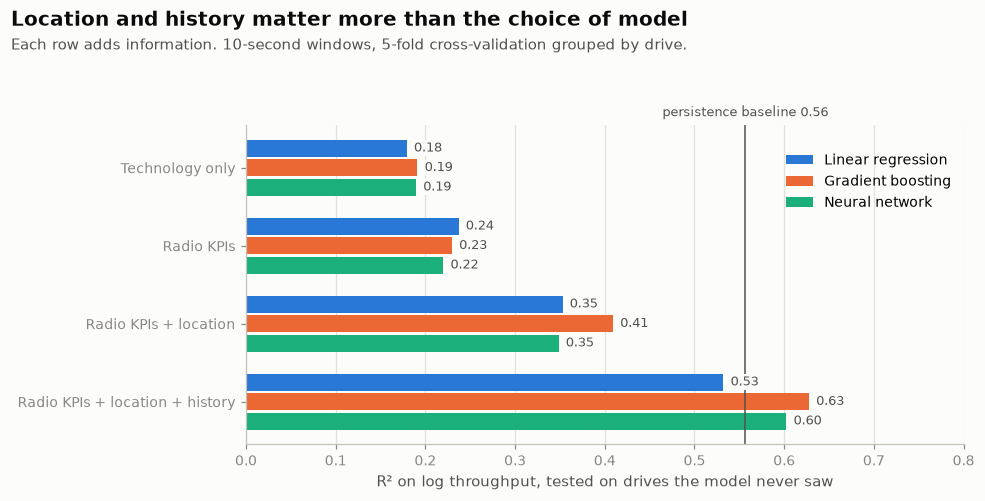

In [22]:
scores, predictions = model.compare_models(windows, folds)
display(scores.pivot(index="features", columns="model", values="r2_log").loc[list(model.FEATURE_SETS)].round(2))
plots.model_scores(scores, model.baseline_scores(windows, folds));

* **Knowing only "5G or LTE" already gives R² ≈ 0.19.** Adding all radio KPIs (RSRP, RSRQ, SNR, CQI, RSSI, neighbour) lifts it only to about 0.23.
* **Adding location gives 0.41.** Where you are says more than what the signal looks like, because location stands for things the phone cannot measure: which cells serve that road, their bandwidth, their load, whether NR is there.
* **Adding the last 10 seconds of throughput gives 0.63.** Gradient boosting and the neural network (0.60) beat persistence (0.56); linear regression (0.53) does not.
* **Model choice matters less than the inputs.** The three models are within 0.10 of each other on every row. The neural network does not beat gradient boosting on 2,400 rows of tabular data, which is the normal result.

The exact values can differ by about 0.01 between library versions.

How stable are these scores? Each of the five test folds can be scored on its own:

In [23]:
radio_prediction = predictions[("Radio KPIs", "Gradient boosting")]
print("R2 per test fold, gradient boosting on radio KPIs:",
      [round(float(value), 2) for value in model.fold_spread(windows, radio_prediction, folds)])

R2 per test fold, gradient boosting on radio KPIs: [0.4, 0.28, 0.24, -0.63, 0.06]


The score depends a lot on which drives are in the test fold: from 0.40 down to -0.63. So a difference of a few hundredths, such as 0.19 against 0.23, is noise. The steps that are larger than this spread are the ones from adding location and history.

In [24]:
honest = scores.set_index(["features", "model"]).loc[("Radio KPIs", "Gradient boosting"), "r2_log"]
leaky = model.random_split_score(windows, model.FEATURE_SETS["Radio KPIs"])["r2_log"]
print(f"Same model, same inputs.  Split by drive: R2 = {honest:.2f}   |   random split: R2 = {leaky:.2f}")

Same model, same inputs.  Split by drive: R2 = 0.23   |   random split: R2 = 0.46


**The split is the most important line of the whole section.** With a random split the same model scores 0.46 instead of 0.23. Neighbouring windows of one drive are almost copies of each other, so a random split lets the model see the answer during training. The honest number is the one tested on new drives.

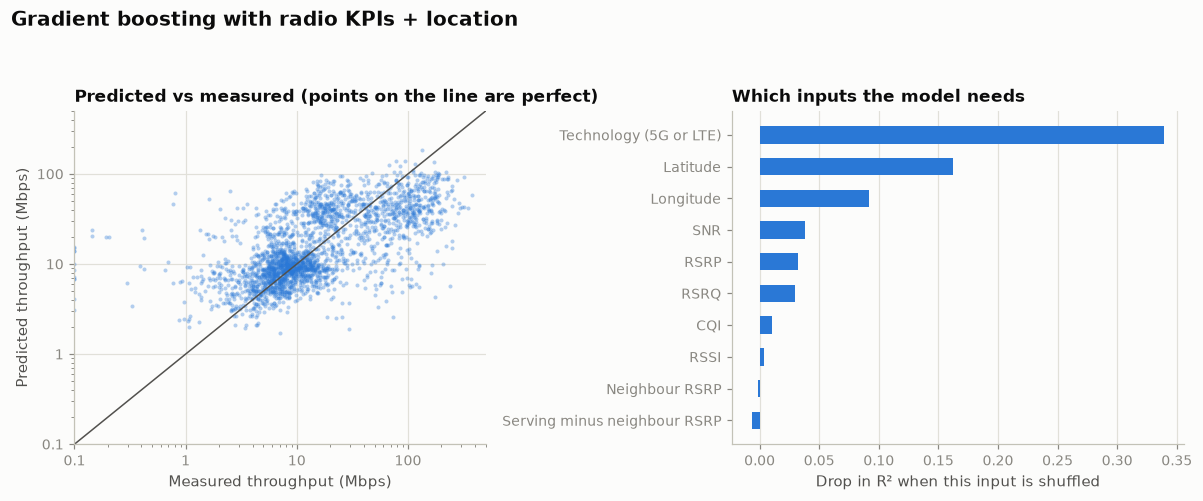

In [25]:
features = model.FEATURE_SETS["Radio KPIs + location"]
importance = model.feature_importance(windows, features)
plots.model_fit(windows, predictions[("Radio KPIs + location", "Gradient boosting")], importance);

The importance plot repeats the story of section 3: technology and location carry the model; SNR, RSRP and RSRQ add a little; CQI adds almost nothing.

**Why this matters for RAN traffic control.** The phone's own measurements explain only a small part of its throughput. The rest depends on things only the network knows: cell load, scheduler decisions, bandwidth, the NR leg. That is the reason traffic control lives in the RAN, and why throughput prediction for a user works much better with recent history than with a snapshot of radio KPIs.

## 7. Summary

| Question | Answer from this data |
|---|---|
| What served the phone? | 5G (NSA) 51% of samples, LTE 33%, 3G 16% |
| Median downlink | 5G 15.9 Mbps, LTE 6.8 Mbps, 3G 2.5 Mbps |
| Coverage | RSRP below -100 dBm in 5.5% of 5G samples and 15% of LTE samples |
| Mobility | 733 cell changes, 1.5 per minute; 148 ping-pong round trips (36% of changes) |
| Cost of a cell change | about 31% dip (interval 5% to 40%); 5G → LTE costs 57% and does not recover |
| Weak spots | 41 road bins with weak coverage, 2 with good coverage but low throughput |
| Prediction | R² 0.23 from radio KPIs, 0.41 with location, 0.63 with history (tested on unseen drives) |

**Limits.** One operator, one city, one phone, winter 2019/20. Application-level log: no RRC signalling, no cell load, no NR-specific KPIs. In 5G rows the radio KPIs most likely describe the LTE anchor. The cost of a change rests on 201 events, so only the moves between 5G and LTE cells are clear. Position is only updated every 100 m.